# 02 · Nelson-Siegel fits of the US Treasury curve

The Nelson-Siegel model describes a whole yield curve with three numbers. This notebook fits it to every trading day since 2001-07-31 (the first day all eleven Treasury maturities exist) with the from-scratch code in `yieldcurve.nelson_siegel`, and asks:

1. what the three loadings look like;
2. how well the model fits, with a fixed λ and with λ optimized each day;
3. when and where it fits badly;
4. whether the three fitted factors behave like the level, slope and curvature one can read directly off the curve.

The daily fits are cached in `data/us_ns_factors.parquet` (`python -m yieldcurve.nelson_siegel` rebuilds them).

In [1]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio

from yieldcurve import nelson_siegel as ns
from yieldcurve import plots
from yieldcurve.data import curve_on, load_us_yields
from yieldcurve.factors import empirical_factors

# Interactive figures in Jupyter / VS Code, plus a static PNG copy so the
# notebook still shows its charts on GitHub.
pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].width = 900
pio.renderers["png"].height = 540

yields = load_us_yields().loc[ns.FULL_CURVE_START :]
months = ns.maturity_months(yields.columns)

## The model

For a maturity of τ months the model yield is

$$y(\tau) = \beta_0 + \beta_1 \frac{1 - e^{-\lambda\tau}}{\lambda\tau} + \beta_2 \left(\frac{1 - e^{-\lambda\tau}}{\lambda\tau} - e^{-\lambda\tau}\right)$$

Each β multiplies a fixed function of maturity, its **loading**. λ sets how fast the loadings decay. Diebold and Li (2006) fix λ = 0.0609, which puts the peak of the third loading near 30 months.

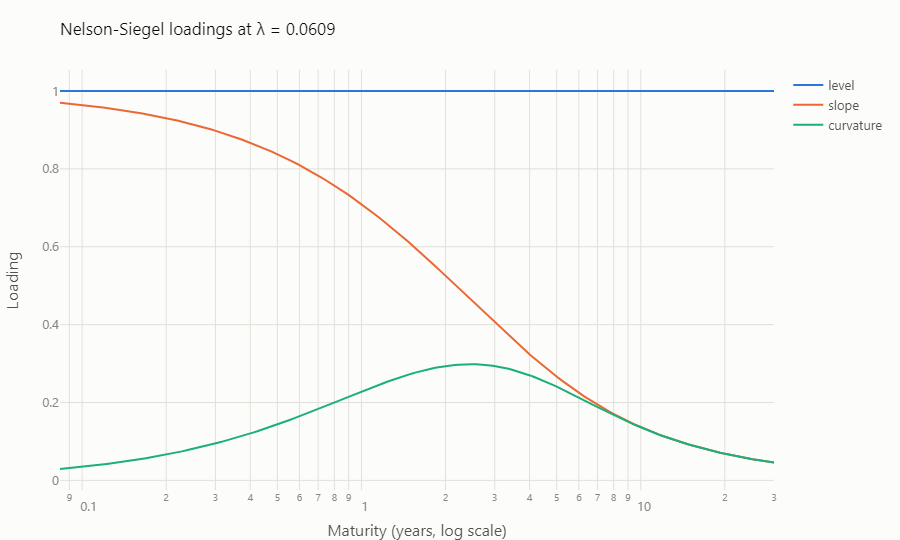

In [2]:
grid = np.geomspace(1, 360, 200)
loadings = ns.ns_loadings(grid)
fig = go.Figure(
    [
        go.Scatter(x=grid / 12, y=loadings[name], name=name, mode="lines", line=dict(width=2))
        for name in ns.FACTOR_COLUMNS
    ]
)
fig.update_layout(
    template=plots.TEMPLATE,
    title="Nelson-Siegel loadings at λ = 0.0609",
    xaxis=dict(title="Maturity (years, log scale)", type="log"),
    yaxis=dict(title="Loading"),
)
fig

- **Level (β0)** loads equally on every maturity. It is also the yield the curve tends to at very long maturities.
- **Slope (β1)** loads fully on the short end and fades with maturity. The short rate is β0 + β1, so **β1 is negative when the curve slopes upward**. Its sign is the opposite of the usual "10Y minus 3M" slope.
- **Curvature (β2)** is zero at both ends and peaks in the middle (about 2.5 years here), so it moves medium maturities against the two ends.

With λ fixed the model is linear in the betas, so `fit_ns_fixed` is an ordinary least squares regression on these three loadings. `fit_ns` also searches for the λ that fits best.

## One day, two fits

Two very different curves: the steep curve at the end of 2008 and the inverted curve at the 2022 hiking peak. Dots are observed yields; lines are the fixed-λ and optimized-λ fits. The legend shows each fit's RMSE in basis points.

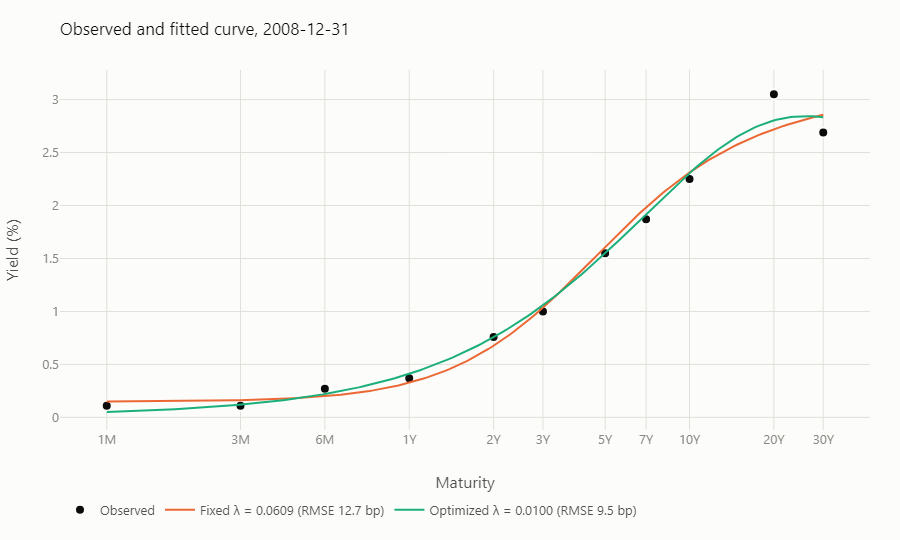

In [3]:
def show_fit(date):
    observed = curve_on(yields, date)
    observed_months = ns.maturity_months(observed.index)
    fits = {
        "Fixed λ": ns.fit_ns_fixed(observed_months, observed),
        "Optimized λ": ns.fit_ns(observed_months, observed),
    }
    curves = {}
    for label, fit in fits.items():
        curve = ns.ns_curve(grid, fit.betas, fit.lam)
        curve.index = grid / 12
        curves[f"{label} = {fit.lam:.4f} (RMSE {fit.rmse * 100:.1f} bp)"] = curve
    return plots.curve_fit(observed, curves, title=f"Observed and fitted curve, {observed.name:%Y-%m-%d}")


show_fit("2008-12-31")

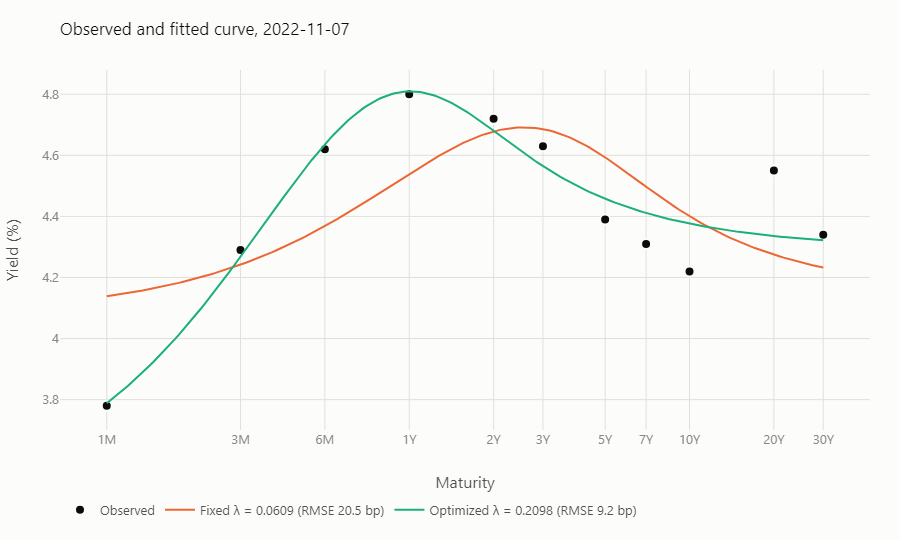

In [4]:
show_fit("2022-11-07")

Two things to notice:

- **The fixed λ puts the hump in the wrong place on the inverted curve.** On 2022-11-07 yields peak at the 1Y, but at λ = 0.0609 the curvature loading peaks near 2.5 years, so the fitted hump sits too far right (RMSE 20.5 bp). The optimized fit moves λ to 0.21, which puts the hump at about 9 months and cuts the error to 9.2 bp.
- **Optimizing λ can change the betas completely.** On 2008-12-31 the optimized fit is only slightly better (9.5 bp against 12.7 bp), but λ lands on the lower bound (0.01) and the curvature beta flips from −3.0 to +4.8. Betas fitted with different λ are not comparable, which matters for the factor time series below.

Neither fit reaches the 20Y point on 2022-11-07: it sits about 30 bp above the 10Y and 20 bp above the 30Y, and a three-factor curve cannot bend that way.

## Every trading day

`load_ns_factors()` returns the fixed-λ fit of every day in the window (cached). The optimized-λ fits are computed here; that takes a few seconds.

In [5]:
fixed = ns.load_ns_factors()
optimized = ns.fit_ns_daily(yields, lam=None)
fixed.tail()

,level,slope,curvature,lam,rmse_bp,n_points
date,,,,,,
2026-09-18,5.318137,-1.309060,0.024148,0.0609,9.715873,11
2026-09-21,5.253066,-1.228664,0.103023,0.0609,10.312780,11
2026-09-22,5.267072,-1.239558,-0.004976,0.0609,9.548799,11
2026-09-23,5.383785,-1.364024,0.285415,0.0609,8.811010,11
2026-09-24,5.471282,-1.411992,0.142927,0.0609,8.944408,11


In [6]:
quantiles = [0.05, 0.25, 0.5, 0.75, 0.95]
rmse = pd.DataFrame({"Fixed λ": fixed["rmse_bp"], "Optimized λ": optimized["rmse_bp"]})
rmse_summary = rmse.describe(percentiles=quantiles).drop("count").round(1)
rmse_summary

,Fixed λ,Optimized λ
mean,10.4,5.6
std,5.1,3.1
min,1.9,1.0
5%,3.8,2.1
25%,6.8,3.6
50%,9.5,4.7
75%,12.7,6.8
95%,20.4,11.1
max,48.7,29.5


**Typical fit error.** With the fixed λ the median daily RMSE is **9.5 bp** (mean 10.4 bp), and on 90% of days it lies between 3.8 and 20.4 bp. Optimizing λ each day roughly halves it: median **4.7 bp**, mean 5.6 bp.

For scale, these yields are published to the nearest basis point, and the curve here runs from 1 month to 30 years. Diebold and Li fitted maturities up to 10 years only, which is an easier job for three factors.

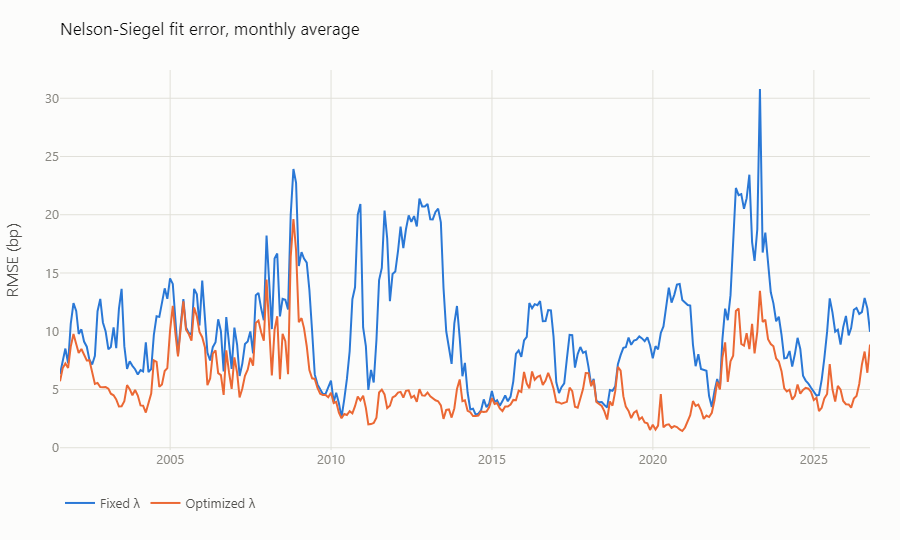

In [7]:
plots.line_chart(
    dict(rmse.items()),
    title="Nelson-Siegel fit error, monthly average",
    y_title="RMSE (bp)",
    unit=" bp",
    freq="ME",
)

### Worst-fit days

The ten days with the largest fixed-λ error, with the optimized-λ error next to it, and the worst one plotted.

In [8]:
worst = fixed.nlargest(10, "rmse_bp")[["rmse_bp", "n_points"]].round(1)
worst["optimized_rmse_bp"] = optimized.loc[worst.index, "rmse_bp"].round(1)
worst["optimized_lam"] = optimized.loc[worst.index, "lam"].round(4)
worst

,rmse_bp,n_points,optimized_rmse_bp,optimized_lam
date,,,,
2023-04-21,48.7,11,13.4,0.5497
2023-04-20,47.6,11,13.4,0.5347
2023-04-24,45.8,11,13.8,0.5486
2023-04-18,38.2,11,13.0,0.4898
2023-04-26,38.1,11,16.0,0.5471
2023-04-19,36.2,11,12.1,0.4468
2007-08-20,35.0,11,25.6,0.5635
2023-04-17,33.8,11,13.0,0.4769
2023-04-25,33.1,11,15.4,0.5117


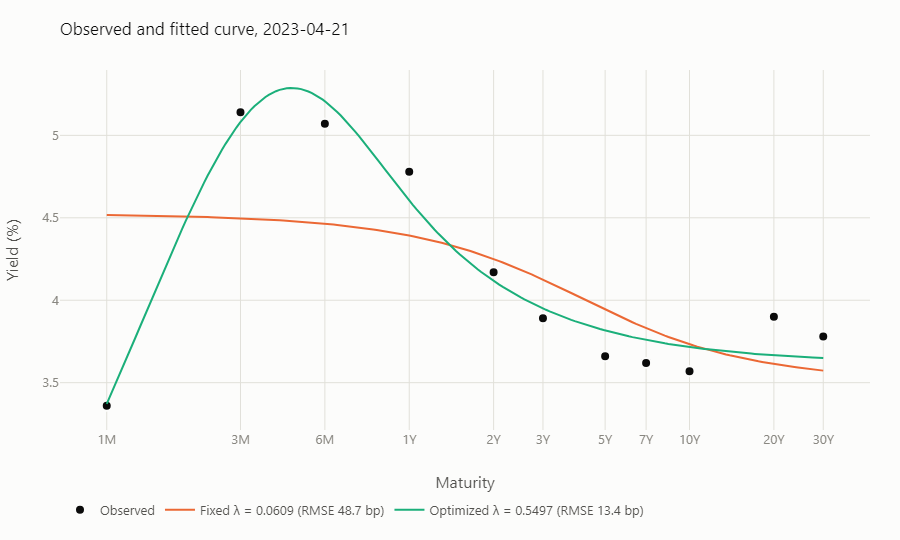

In [9]:
show_fit(worst.index[0])

In [10]:
yearly = rmse.groupby(rmse.index.year).mean().round(1)
yearly.T

date,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Fixed λ,9.1,9.7,8.7,10.1,11.4,9.0,10.5,15.7,9.0,9.2,...,7.5,5.0,9.0,11.9,7.2,16.6,15.9,7.0,9.0,11.4
Optimized λ,7.8,6.8,4.5,5.7,10.4,6.7,8.2,11.0,6.3,3.4,...,4.5,4.5,2.7,2.0,3.4,8.6,9.4,4.8,4.5,5.7


- **Nine of the ten worst days are in April 2023**, during the debt-ceiling standoff. On 2023-04-21 the 1M bill yielded 3.36% while the 3M yielded 5.14%. A 178 bp step between two neighbouring points is a market dislocation, not a curve shape, and no smooth curve fits it. April 2023 is also the worst month (average 30.8 bp).
- **The other one is 2007-08-20**, in the first weeks of the credit crisis, when money ran into bills: the 1M was at 2.47% and the 3M at 3.12%, against 4.17% for the 6M.
- **By year, the fixed-λ fit is worst in 2012 (19.5 bp)**, followed by 2022, 2023 and 2008 (about 16 bp each), and best in 2014 (4.1 bp). 2012 is not a stress year. With the Fed at zero and promising to stay there, yields were flat near zero out to two or three years and only then rose. The fixed-λ loadings cannot stay flat that long; the optimized fit handles it (see the chart: about 4 bp in 2012).
- **6.3% of days have a fixed-λ error above 20 bp.** They cluster in the episodes above: late 2008, 2011–13, and 2022–23.

### Where the model misses

Residuals (observed minus fitted, in basis points) by maturity for the fixed-λ fits. A mean far from zero is a systematic miss, not noise.

In [11]:
residuals_bp = (yields - ns.fitted_yields(fixed, yields.columns)) * 100
pd.DataFrame(
    {
        "mean": residuals_bp.mean(),
        "mean_abs": residuals_bp.abs().mean(),
        "mean_since_2020": residuals_bp.loc["2020":].mean(),
    }
).round(1).T

,1M,3M,6M,1Y,2Y,3Y,5Y,7Y,10Y,20Y,30Y
mean,-10.5,-2.2,8.0,10.9,6.4,-2.0,-10.1,-9.6,-9.2,10.1,8.2
mean_abs,11.6,3.4,9.0,12.0,6.8,3.5,10.8,10.5,9.4,11.3,10.2
mean_since_2020,-13.1,-0.6,9.0,11.3,6.7,-0.8,-11.4,-11.2,-12.6,14.8,7.7


- **The misses are systematic, not random.** For most maturities the mean residual is almost as large as the mean absolute residual, so the error has the same sign nearly every day.
- **They form a wave along the curve.** The fitted curve is too high at the 1M (−10.5 bp), too low from 6M to 2Y (+6 to +11 bp), too high from 5Y to 10Y (about −10 bp) and too low at 20Y and 30Y (+10 and +8 bp). The 3M and 3Y, where the wave crosses zero, are fitted within about 2 bp. Three factors give one hump; the data want a second bend.
- **The 20Y kink from notebook 01 is real and has grown.** The 20Y sits 10 bp above the fitted curve on average, 15 bp since 2020, and more than 20 bp in 2022 and 2023. In 2014–2018 the gap was close to zero.

### What λ does the data want?

The optimized λ per day (monthly average), against the fixed 0.0609.

In [12]:
lam_low, lam_high = ns.LAMBDA_BOUNDS
lam_stats = pd.Series(
    {
        "median": optimized["lam"].median(),
        "5th percentile": optimized["lam"].quantile(0.05),
        "95th percentile": optimized["lam"].quantile(0.95),
        "share at lower bound": (optimized["lam"] < lam_low * 1.001).mean(),
        "share at upper bound": (optimized["lam"] > lam_high * 0.999).mean(),
        "share of days within 1 bp of fixed-λ RMSE": (rmse["Fixed λ"] - rmse["Optimized λ"] < 1).mean(),
    }
).round(4)
lam_stats

median                                       0.0409
5th percentile                               0.0100
95th percentile                              0.2491
share at lower bound                         0.0501
share at upper bound                         0.0065
share of days within 1 bp of fixed-λ RMSE    0.2180
dtype: float64

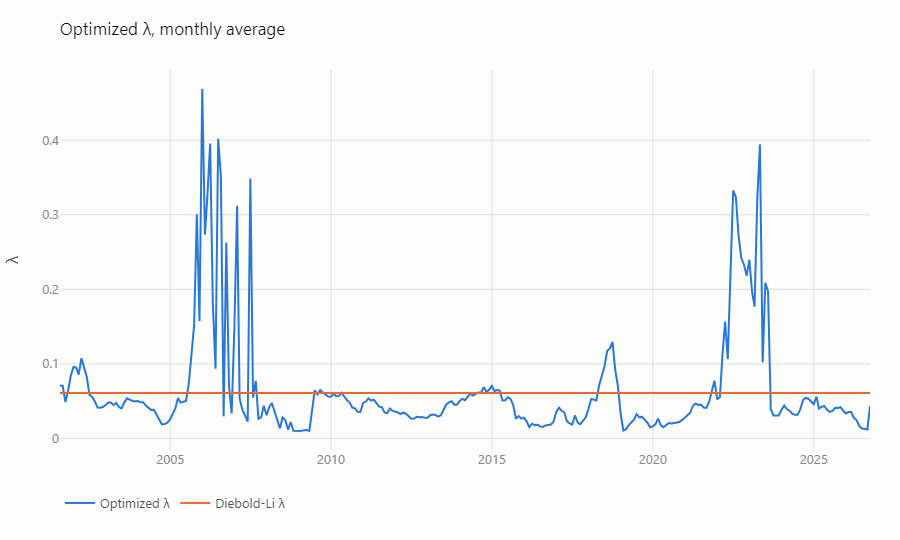

In [13]:
plots.line_chart(
    {
        "Optimized λ": optimized["lam"],
        "Diebold-Li λ": pd.Series(ns.DIEBOLD_LI_LAMBDA, index=optimized.index),
    },
    title="Optimized λ, monthly average",
    y_title="λ",
    freq="ME",
)

- **Most of the time the data want a slightly smaller λ than Diebold-Li's.** The median optimized λ is 0.041, which puts the curvature hump near 44 months instead of 30.
- **λ jumps when the curve is flat or inverted.** In 2006–07 and 2022–23 the monthly average climbs to 0.3–0.45: the hump moves to the very short end, as in the 2022 example above.
- **λ is often poorly pinned down.** On 5% of days it sits on the lower bound, and on 22% of days optimizing it improves the RMSE by less than 1 bp.

So the choice is a trade-off. The optimized λ fits each day better, but the betas then mean something different from day to day. For factor time series, the PCA comparison (Phase 4) and forecasting (Phase 5), the **fixed-λ betas** are the ones to use, which is the reason Diebold and Li fixed λ in the first place.

## Factors vs. empirical proxies

Diebold and Li compare the fitted betas with three quantities read directly off the curve (`yieldcurve.factors.empirical_factors`):

- level: the average of the 3M, 2Y and 10Y yields (the 10Y and 30Y alone are also compared);
- slope: 10Y − 3M, compared with **−β1** because of the sign convention above;
- curvature: 2·2Y − 3M − 10Y. In the model this combination equals about 0.37·β2, so β2 is scaled by that loading before comparing.

In [14]:
proxies = empirical_factors(yields)
at = ns.ns_loadings([3, 24, 120])["curvature"]
curvature_scale = 2 * at[24] - at[3] - at[120]

PAIRS = {
    "level": (fixed["level"], proxies["level"]),
    "level vs 10Y": (fixed["level"], yields["10Y"]),
    "level vs 30Y": (fixed["level"], yields["30Y"]),
    "slope": (-fixed["slope"], proxies["slope"]),
    "curvature": (curvature_scale * fixed["curvature"], proxies["curvature"]),
}
comparison = pd.DataFrame(
    {
        name: {
            "correlation": model.corr(proxy),
            "correlation of daily changes": model.diff().corr(proxy.diff()),
            "mean gap (pp)": (model - proxy).mean(),
            "mean absolute gap (pp)": (model - proxy).abs().mean(),
        }
        for name, (model, proxy) in PAIRS.items()
    }
).round(3)
print(f"curvature scale: {curvature_scale:.3f}")
comparison

curvature scale: 0.370


,level,level vs 10Y,level vs 30Y,slope,curvature
correlation,0.598,0.915,0.989,0.996,0.979
correlation of daily changes,0.691,0.912,0.972,0.926,0.849
mean gap (pp),1.598,0.757,0.140,0.693,-0.240
mean absolute gap (pp),1.675,0.763,0.176,0.712,0.248


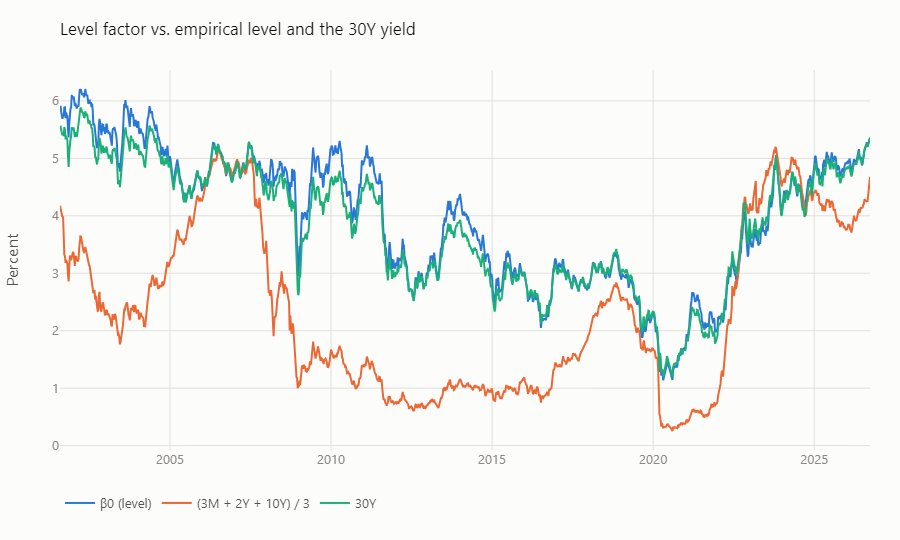

In [15]:
def compare(name, model_label, proxy_label, **kwargs):
    model, proxy = PAIRS[name]
    return plots.line_chart(
        {model_label: model, proxy_label: proxy}, y_title="Percentage points", unit=" pp", freq="W-FRI", **kwargs
    )


plots.line_chart(
    {"β0 (level)": fixed["level"], "(3M + 2Y + 10Y) / 3": proxies["level"], "30Y": yields["30Y"]},
    title="Level factor vs. empirical level and the 30Y yield",
    y_title="Percent",
    unit="%",
    freq="W-FRI",
)

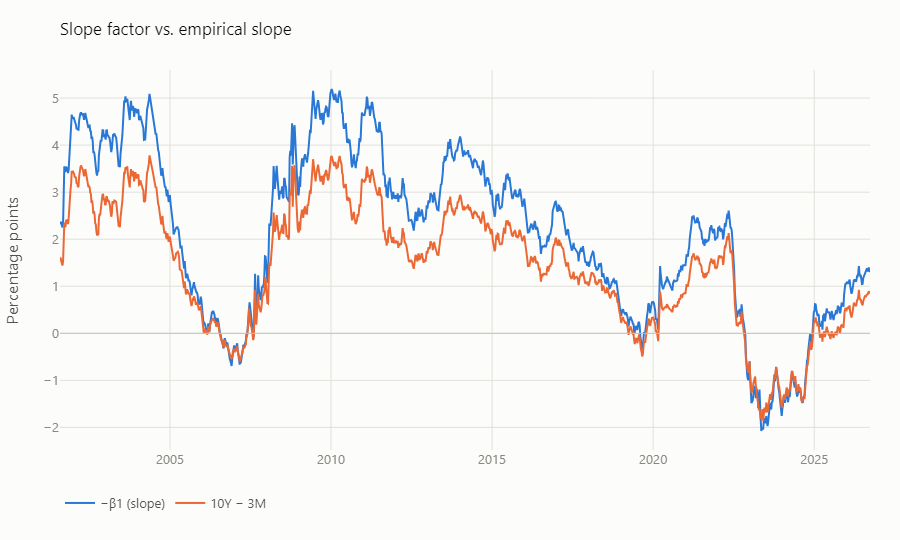

In [16]:
compare("slope", "−β1 (slope)", "10Y − 3M", title="Slope factor vs. empirical slope", zero_line=True)

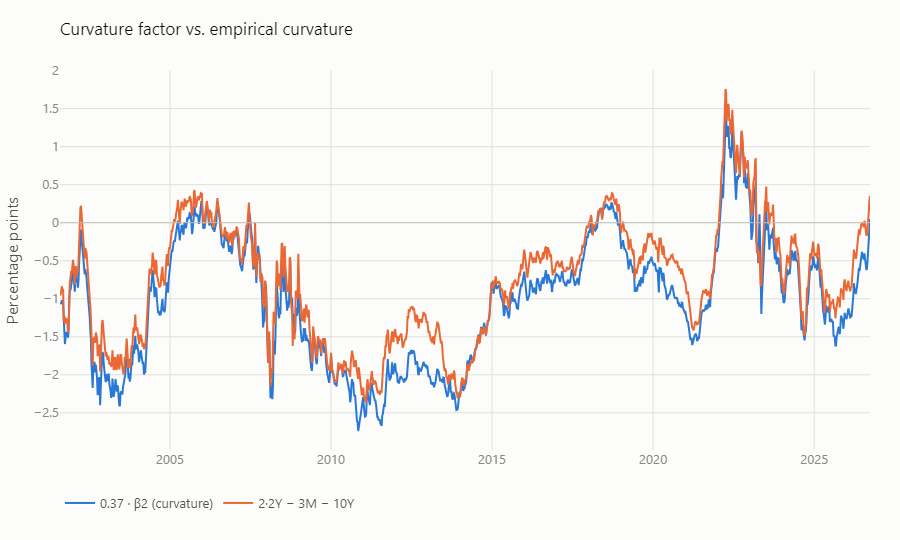

In [17]:
compare(
    "curvature",
    f"{curvature_scale:.2f} · β2 (curvature)",
    "2·2Y − 3M − 10Y",
    title="Curvature factor vs. empirical curvature",
    zero_line=True,
)

- **Slope and curvature track their proxies closely.** −β1 and 10Y − 3M have a correlation of 0.996 (0.93 in daily changes); scaled β2 and 2·2Y − 3M − 10Y have 0.979 (0.85 in daily changes).
- **The fitted slope is wider than 10Y − 3M** by 0.69 pp on average. −β1 is the gap between the model's limits at zero and infinite maturity, which spans more than the 3M-to-10Y stretch.
- **The level factor does not match Diebold and Li's level proxy here.** Its correlation with the 3M/2Y/10Y average is only 0.60. β0 is the yield the curve tends to at long maturities, and with maturities out to 30 years it follows the long end: correlation 0.92 with the 10Y and 0.99 with the 30Y, which it exceeds by 0.14 pp on average. The three-maturity average includes the 3M bill, which spent 2009–2015 and 2020–21 near zero while long yields did not.

So on a curve that extends to 30 years, **level means "the long end"**, not "the average yield". That is worth remembering when the factors are compared with PCA components in Phase 4.

## Looking up one day

`get_ns_factors(date)` returns the cached fit for the last trading day on or before a date. It is the helper the Phase 8 agent tool will call. 2022-11-06 was a Sunday, so it rolls back to Friday.

In [18]:
ns.get_ns_factors("2022-11-06")

level         4.083712
slope        -0.070669
curvature     1.972144
lam           0.060900
rmse_bp      20.238369
n_points     11.000000
Name: 2022-11-04 00:00:00, dtype: float64

## Summary

- **Fit quality:** the fixed-λ Nelson-Siegel fit has a median RMSE of 9.5 bp across 6,290 trading days and eleven maturities; optimizing λ daily brings it to 4.7 bp.
- **Where it fails:** dislocations at the bill end (April 2023, August 2007), the zero-rate years when the front of the curve was flat (2011–13), and inverted curves whose hump is at the short end (2022–23).
- **Systematic residuals:** a wave of about ±10 bp along the curve, including a persistent 20Y kink. A fourth factor (the Svensson extension) is the standard answer; it is not implemented here.
- **Factors:** slope and curvature match their empirical proxies (correlations 0.996 and 0.979). The level factor tracks the 30Y (0.99), not the short/medium/long average.
- **Which λ:** fixed λ for anything that compares betas over time; optimized λ only when the goal is the best fit of a single day.